# Systemy AI – Laboratorium 5
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [68]:
# Twoje rozwiązanie
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
print(df.shape)
print()
print()
print(df.head())
print()
print()
print(df.describe())

(768, 9)


   pregnancies  glucose  blood_pressure  skin_thickness  insulin   bmi  \
0            6      148              72              35        0  33.6   
1            1       85              66              29        0  26.6   
2            8      183              64               0        0  23.3   
3            1       89              66              23       94  28.1   
4            0      137              40              35      168  43.1   

   pedigree  age  outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  


       pregnancies     glucose  blood_pressure  skin_thickness     insulin  \
count   768.000000  768.000000      768.000000      768.000000  768.000000   
mean      3.845052  120.894531       69.105469       20.536458   79.799479   
std       3.369578   31.972618       19.355807       15.952218  115.244002   
min       0.000000    0.000000        0.000000        0.000000

In [69]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

pregnancies       111
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome           500
dtype: int64
outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


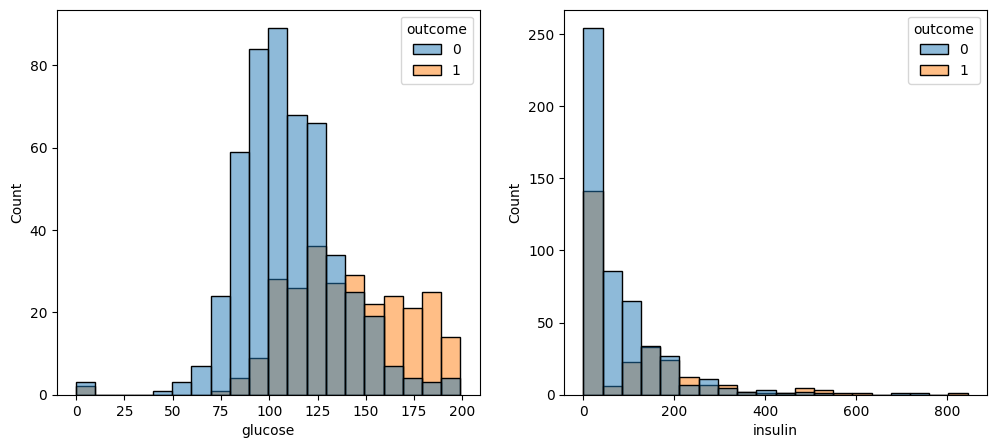

In [70]:
# Twoje rozwiązanie
class_share = df["outcome"].value_counts(normalize=True)
zeros = (df == 0).sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="glucose", hue="outcome", ax=axes[0], bins=20)
sns.histplot(data=df, x="insulin", hue="outcome", ax=axes[1], bins=20)

print(zeros)
print(class_share)

In [71]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


*Twoja odpowiedź:*
1. Jaką accuracy osiągnie baseline?

Będzie mieć wartość ok. 0.65.

2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?

Glucose, blood_pressure, skin_thickness, insulin, bmi muszą być niezerowe.
Normalne jest to natomiast dla pregnancies.

3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?

Taką cechą jest glucose. Osoby z cukrzycą mają większe stężenie glukozy w krwi od osób zdrowych.

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [72]:
# Twoje rozwiązanie
cols_with_zeros = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
df_clean = df.copy()
df_clean[cols_with_zeros] = df_clean[cols_with_zeros].replace(0, np.nan)
missing = df_clean.isna().sum()
print(missing)

pregnancies         0
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome             0
dtype: int64


In [73]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?

Można usunąć kolumnę insulin, usunąć wiersze z brakami, uzupełnienie braków, np. medianą, czy dodać informację o brakach. Wybieram uzupełnienie medianą. Zapobiega to wyciekowi danych przy walidacji.

---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [74]:
# Twoje rozwiązanie
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X = df_clean.drop("outcome", axis=1)
y = df_clean["outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(X_train.shape)

def model_z(klasyfikator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", klasyfikator)
    ])

cv = StratifiedKFold(n_splits=5, shuffle= True, random_state=42)

(576, 8)


In [75]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

                     CV średnia  CV odch.     train
baseline               0.651049  0.002249  0.651042
regresja logistyczna   0.777856  0.024709  0.789931
kNN                    0.736132  0.020716  0.835069
drzewo decyzyjne       0.713568  0.024244       1.0
las losowy             0.748291  0.014015       1.0


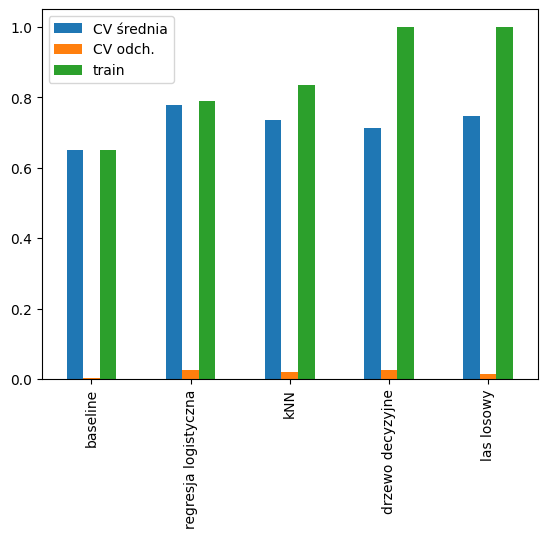

In [76]:
# Twoje rozwiązanie
#accuracy poziomo, accuracy(CV, srednia +- odchylenie)
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

porownanie = pd.DataFrame(columns=["CV średnia", "CV odch.", "train"], index=["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"])

bas_model = DummyClassifier(strategy="most_frequent")
bas_score = cross_val_score(bas_model, X_train, y_train, cv=cv, scoring="accuracy")
porownanie.loc["baseline", "CV średnia"] = bas_score.mean()
porownanie.loc["baseline", "CV odch."] = bas_score.std()
porownanie.loc["baseline", "train"] = bas_model.fit(X_train, y_train).score(X_train, y_train)

reg_model = model_z(LogisticRegression())
reg_score = cross_val_score(reg_model, X_train, y_train, cv=cv, scoring="accuracy")
porownanie.loc["regresja logistyczna", "CV średnia"] = reg_score.mean()
porownanie.loc["regresja logistyczna", "CV odch."] = reg_score.std()
porownanie.loc["regresja logistyczna", "train"] = reg_model.fit(X_train, y_train).score(X_train, y_train)

knn_model = model_z(KNeighborsClassifier())
knn_score = cross_val_score(knn_model, X_train, y_train, cv=cv, scoring="accuracy")
porownanie.loc["kNN", "CV średnia"] = knn_score.mean()
porownanie.loc["kNN", "CV odch."] = knn_score.std()
porownanie.loc["kNN", "train"] = knn_model.fit(X_train, y_train).score(X_train, y_train)

tree_model = model_z(DecisionTreeClassifier(random_state=42))
tree_score = cross_val_score(tree_model, X_train, y_train, cv=cv, scoring="accuracy")
porownanie.loc["drzewo decyzyjne", "CV średnia"] = tree_score.mean()
porownanie.loc["drzewo decyzyjne", "CV odch."] = tree_score.std()
porownanie.loc["drzewo decyzyjne", "train"] = tree_model.fit(X_train, y_train).score(X_train, y_train)

forest_model = model_z(RandomForestClassifier(random_state=42))
forest_score = cross_val_score(forest_model, X_train, y_train, cv=cv, scoring="accuracy")
porownanie.loc["las losowy", "CV średnia"] = forest_score.mean()
porownanie.loc["las losowy", "CV odch."] = forest_score.std()
porownanie.loc["las losowy", "train"] = forest_model.fit(X_train, y_train).score(X_train, y_train)

print(porownanie[["CV średnia", "CV odch.", "train"]])

porownanie.plot(kind="bar", y=["CV średnia", "CV odch.", "train"])
plt.show()

In [77]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

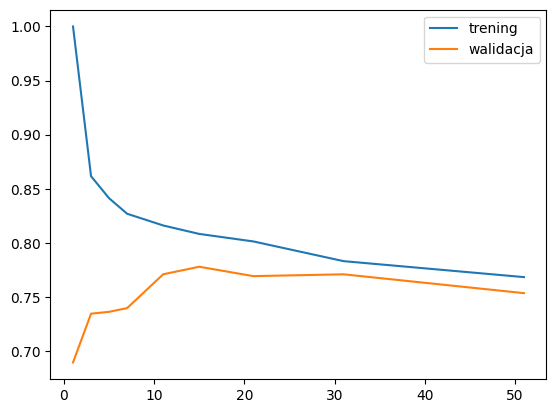

In [78]:
# Twoje rozwiązanie
from sklearn.model_selection import validation_curve

ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]
tren, walid = validation_curve(model_z(KNeighborsClassifier()), X_train, y_train, param_name="model__n_neighbors", param_range=ks, cv=cv, scoring="accuracy")

tr = tren.mean(axis=1)
wal = walid.mean(axis=1)
plt.plot(ks, tr, label="trening")
plt.plot(ks, wal, label="walidacja")
plt.legend()

In [79]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:* dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0? Gdzie jest przeuczenie, a gdzie niedouczenie?
  
  Ponieważ kNN szuka jednego najbliższego sąsiada, a oceniamy go na zbiorze treningowym, więc najbliższym sąsiadem dla każdego punktu treningowego jest on sam. Stąd jest idealne dopasowanie klasy.

   Przeuczenie występuje dla bardzo małych wartości k. Dokładność na zbiorze treningowym jest ekstremalnie wysoka, ale na zbiorze walidacyjnym jest znacznie niższa. Model dopasowuje się do szumu w danych.
   Niedouczenie natomiast występuje przy zbyt dużych wartościach k. Zarówno dokładność treningowa, jak i walidacyjna wyraźnie wtedy spadają, ponieważ model traci zdolność do wychwytywania wzorców.

---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [80]:
# Twoje rozwiązanie
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

siatki = {
    "regresja logistyczna": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "kNN": {"model__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]},
    "drzewo decyzyjne": {"model__max_depth": [2, 3, 4, 5, 6, 8, None]},
    "las losowy": {"model__max_depth": [3, 5, 8, None], "model__n_estimators": [100, 300]}
}

modele = {
    "regresja logistyczna": LogisticRegression(),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42)
}

wyniki_gs = {}
for model_nazwa, siatka in siatki.items():
    model = model_z(modele[model_nazwa])
    gs = GridSearchCV(model, siatka, cv=cv, scoring="accuracy")
    gs.fit(X_train, y_train)
    wyniki_gs[model_nazwa] = gs
    print(f"Najlepsze parametry dla {model_nazwa}: {gs.best_params_}")
    print(f"Najlepszy wynik dla {model_nazwa}: {gs.best_score_}")

Najlepsze parametry dla regresja logistyczna: {'model__C': 1}
Najlepszy wynik dla regresja logistyczna: 0.777856071964018
Najlepsze parametry dla kNN: {'model__n_neighbors': 15}
Najlepszy wynik dla kNN: 0.7778110944527736
Najlepsze parametry dla drzewo decyzyjne: {'model__max_depth': 5}
Najlepszy wynik dla drzewo decyzyjne: 0.7499700149925037
Najlepsze parametry dla las losowy: {'model__max_depth': 3, 'model__n_estimators': 300}
Najlepszy wynik dla las losowy: 0.76215892053973


In [81]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

regresja logistyczna
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(C=1))])
0.7239583333333334


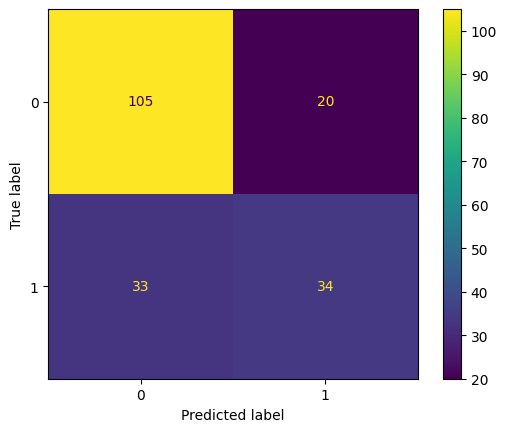

              precision    recall  f1-score   support

           0       0.76      0.84      0.80       125
           1       0.63      0.51      0.56        67

    accuracy                           0.72       192
   macro avg       0.70      0.67      0.68       192
weighted avg       0.72      0.72      0.72       192



In [82]:
# Twoje rozwiązanie
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_
print(najlepszy)
print(model_koncowy)

acc_test = model_koncowy.score(X_test, y_test)
print(acc_test)

y_pred = model_koncowy.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()
print(classification_report(y_test, y_pred))

In [83]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


*Twoja odpowiedź:*
1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki – ile p.p. to jedna osoba?)

Z walidacji krzyżowej ok. 0.778 (77.8%), na zbiorze testowym ok. 0.724 (72.4%). Testowy wynik jest niższy od tego z walidacji. Nie jest to niepokojąca różnica. Jedna osoba to ok. 0.52 p.p.

2. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?

Wynosi 0.51. Oznacza on, że prawie połowa przypadków nie zostanie wykryta, co wiąże się opóźnieniem leczenia. W tym zastosowaniu accuracy nie jest dobrą metryką.

3. Modele w czołówce różnią się w CV o 1–2 p.p., a odchylenia wynoszą ok. 2–3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?

Nie bardzo. Tak małe różnice nie są istotne z punktu widzenia statystyki.


---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?

In [84]:
# Twoje rozwiązanie
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

siatki = {
    "regresja logistyczna": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "kNN": {"model__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]},
    "drzewo decyzyjne": {"model__max_depth": [2, 3, 4, 5, 6, 8, None]},
    "las losowy": {"model__max_depth": [3, 5, 8, None], "model__n_estimators": [100, 300]}
}

modele = {
    "regresja logistyczna": LogisticRegression(),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42)
}

wyniki_gs = {}
for model_nazwa, siatka in siatki.items():
    model = model_z(modele[model_nazwa])
    gs = GridSearchCV(model, siatka, cv=cv, scoring="recall")
    gs.fit(X_train, y_train)
    wyniki_gs[model_nazwa] = gs
    print(f"Najlepsze parametry dla {model_nazwa}: {gs.best_params_}")
    print(f"Najlepszy wynik dla {model_nazwa}: {gs.best_score_}")

Najlepsze parametry dla regresja logistyczna: {'model__C': 1}
Najlepszy wynik dla regresja logistyczna: 0.5825609756097561
Najlepsze parametry dla kNN: {'model__n_neighbors': 3}
Najlepszy wynik dla kNN: 0.5971951219512196
Najlepsze parametry dla drzewo decyzyjne: {'model__max_depth': 4}
Najlepszy wynik dla drzewo decyzyjne: 0.6517073170731708
Najlepsze parametry dla las losowy: {'model__max_depth': None, 'model__n_estimators': 100}
Najlepszy wynik dla las losowy: 0.5823170731707317


drzewo decyzyjne
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 DecisionTreeClassifier(max_depth=4, random_state=42))])
0.75


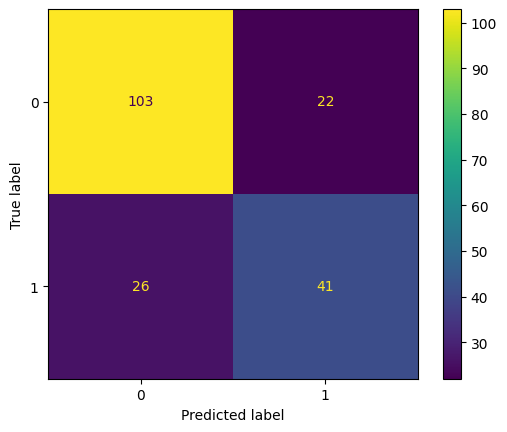

              precision    recall  f1-score   support

           0       0.80      0.82      0.81       125
           1       0.65      0.61      0.63        67

    accuracy                           0.75       192
   macro avg       0.72      0.72      0.72       192
weighted avg       0.75      0.75      0.75       192



In [85]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_
print(najlepszy)
print(model_koncowy)

acc_test = model_koncowy.score(X_test, y_test)
print(acc_test)

y_pred = model_koncowy.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()
print(classification_report(y_test, y_pred))

Zmienił się wybrany model na drzewo decyzyjne. Precison się zwiększyło.

In [86]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X = df_clean.drop("outcome", axis=1)
y = df_clean["outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(X_train.shape)

def model_z(klasyfikator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("model", klasyfikator)
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

(576, 8)


In [87]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

siatki = {
    "regresja logistyczna": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "kNN": {"model__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]},
    "drzewo decyzyjne": {"model__max_depth": [2, 3, 4, 5, 6, 8, None]},
    "las losowy": {"model__max_depth": [3, 5, 8, None], "model__n_estimators": [100, 300]}
}

modele = {
    "regresja logistyczna": LogisticRegression(),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42)
}

wyniki_gs = {}
for model_nazwa, siatka in siatki.items():
    model = model_z(modele[model_nazwa])
    gs = GridSearchCV(model, siatka, cv=cv, scoring="accuracy")
    gs.fit(X_train, y_train)
    wyniki_gs[model_nazwa] = gs
    print(f"Najlepsze parametry dla {model_nazwa}: {gs.best_params_}")
    print(f"Najlepszy wynik dla {model_nazwa}: {gs.best_score_}")

Najlepsze parametry dla regresja logistyczna: {'model__C': 0.1}
Najlepszy wynik dla regresja logistyczna: 0.7691304347826087
Najlepsze parametry dla kNN: {'model__n_neighbors': 11}
Najlepszy wynik dla kNN: 0.7569265367316341
Najlepsze parametry dla drzewo decyzyjne: {'model__max_depth': 5}
Najlepszy wynik dla drzewo decyzyjne: 0.7517091454272864
Najlepsze parametry dla las losowy: {'model__max_depth': 8, 'model__n_estimators': 100}
Najlepszy wynik dla las losowy: 0.7586956521739131


regresja logistyczna
Pipeline(steps=[('imputer',
                 SimpleImputer(add_indicator=True, strategy='median')),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(C=0.1))])
0.7291666666666666


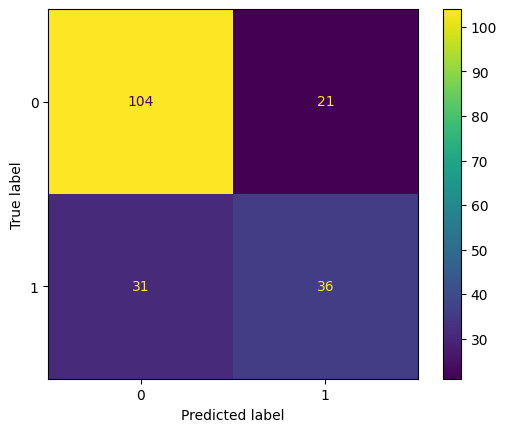

              precision    recall  f1-score   support

           0       0.77      0.83      0.80       125
           1       0.63      0.54      0.58        67

    accuracy                           0.73       192
   macro avg       0.70      0.68      0.69       192
weighted avg       0.72      0.73      0.72       192



In [88]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_
print(najlepszy)
print(model_koncowy)

acc_test = model_koncowy.score(X_test, y_test)
print(acc_test)

y_pred = model_koncowy.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()
print(classification_report(y_test, y_pred))

Sam brak pomiaru daje informację.

In [89]:
X_raw = df.drop("outcome", axis=1)
y_raw = df["outcome"]
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.25, stratify=y_raw, random_state=42
)

def model_wo(klasyfikator):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", klasyfikator)
    ])

wyniki_gs_raw = {}
for model_nazwa, siatka in siatki.items():
    siatka_clean = {k: v for k, v in siatka.items() if not k.startswith("imputer__")}
    model = model_wo(modele[model_nazwa])
    gs = GridSearchCV(model, siatka_clean, cv=cv, scoring="accuracy")
    gs.fit(X_train_raw, y_train_raw)
    wyniki_gs_raw[model_nazwa] = gs
    print(f"Najlepsze parametry dla {model_nazwa}: {gs.best_params_}")
    print(f"Najlepszy wynik CV: {gs.best_score_}")

Najlepsze parametry dla regresja logistyczna: {'model__C': 10}
Najlepszy wynik CV: 0.7795652173913042
Najlepsze parametry dla kNN: {'model__n_neighbors': 11}
Najlepszy wynik CV: 0.7551874062968515
Najlepsze parametry dla drzewo decyzyjne: {'model__max_depth': 2}
Najlepszy wynik CV: 0.7395952023988006
Najlepsze parametry dla las losowy: {'model__max_depth': 3, 'model__n_estimators': 100}
Najlepszy wynik CV: 0.7621739130434783


regresja logistyczna
Pipeline(steps=[('imputer',
                 SimpleImputer(add_indicator=True, strategy='median')),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(C=0.1))])
0.7291666666666666


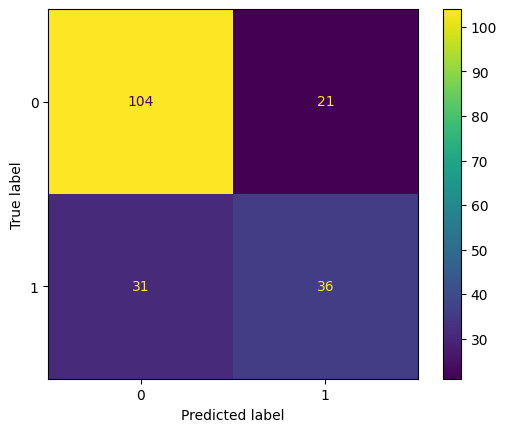

              precision    recall  f1-score   support

           0       0.77      0.83      0.80       125
           1       0.63      0.54      0.58        67

    accuracy                           0.73       192
   macro avg       0.70      0.68      0.69       192
weighted avg       0.72      0.73      0.72       192



In [90]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs_raw[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_
print(najlepszy)
print(model_koncowy)

acc_test = model_koncowy.score(X_test, y_test)
print(acc_test)

y_pred = model_koncowy.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()
print(classification_report(y_test, y_pred))

Jest mała różnica. Jest tak, gdyż wartość 0 może być interpretowana jako brak danych przez algorytmy.